# Perform a looping with a quadrotor

# Goal of the project

The goal of this project is to control a 2D quadrotor to get it to perform acrobatic moves. The controller will be designed using an SQP solver.

Please submit your code as a runnable Jupyter Notebook.

## 2D quadrotor

The quadrotor is depicted in the following figure
<img src='quadrotor.png' width="300">


The quadrotor model is written as
$$\begin{align} 
\dot{p_x} &= v_x\\
m \dot{v}_x &= - (u_1 + u_2) \sin \theta \\ 
\dot{p_y} &= v_y\\
m \dot{v}_y &= (u_1 + u_2) \cos \theta  - m g\\
\dot{\theta} &= \omega\\
I \dot{\omega} &= r (u_1 - u_2) \end{align}$$
where $p_x$ is the horizontal and $p_y$ the vertical positions of the quadrotor and $\theta$ is its orientation with respect to the horizontal plane. $v_x$ and $v_y$ are the linear velocities and $\omega$ is the angular velocity of the robot. $u_1$ and $u_2$ are the forces produced by the rotors (our control inputs). $m$ is the quadrotor mass, $I$ its moment of inertia (a scalar), $r$ is the distance from the center of the robot frame to the propellers and $g$ is the gravity constant. To denote the entire state, we will write $x = [p_x, v_x, p_y, v_y, \theta, \omega]^T$ - we will also write $u = [u_1, u_2]^T$.

The module ```quadrotor.py``` defines the problem and provides all the useful information about the robot and methods to simulate and animate it as shown below.

You can access the different parameters of the model in the following way:

In [2]:
import quadrotor1

print("Mass    =", quadrotor1.MASS)
print("Length  =", quadrotor1.LENGTH)
print("Inertia =", quadrotor1.INERTIA)
print("Dt      =", quadrotor1.DT)
print("state size   =", quadrotor1.DIM_STATE)
print("control size =", quadrotor1.DIM_CONTROL)

Mass    = 0.5
Length  = 0.15
Inertia = 0.1
Dt      = 0.04
state size   = 6
control size = 2




## Part 1 - Setting up the trajectory optimization problem (50 points)
1. Discretize the system dynamics using Euler's method seen in class - write the time discretization step as $\Delta t$ (use symbols not numbers for the mass, etc)
2. We would like the quadrotor to perfom a looping (i.e. a back or front flip). Find and implement a suitable cost function to perform a looping and add constraints to maintain the thrust of each rotor between $0$ and $10$. Solve the problem using your own implementation of a SQP with a long horizon to ensure that you can do a looping.
3. Show plots of all the states and controls of the robot as a function of time. Plot the value of $\alpha$ (during line search) at each iteration of the solver as well as the amount of constraint violation per iteration and the cost per iteration of the solver (also useful to help you debug).
5. Describe your design choices (in a concise manner) in the report.

To visualize the trajectory, use the ```quadrotor.animate_robot``` function and show the animation (show the plots in your report).

### Tips to implement a SQP solver
1. Write down the algorithm (in words not in code), i.e. write all the steps you need to take
2. Write the gradient of the running cost at a given guess $\bar{x} = [{\bar{p}_x}_0, {\bar{v}_x}_0, {\bar{p}_y}_0, {\bar{v}_{y}}_0, \bar{\theta}_0, \bar{\omega}_0, {\bar{u}_1}_0, {\bar{u}_2}_0, \dots, {\bar{p}_x}_N, {\bar{v}_x}_N, {\bar{p}_y}_N, {\bar{v}_{y}}_N, \bar{\theta}_N, \bar{\omega}_N, {\bar{u}_1}_N, {\bar{u}_2}_N,]^T$, i.e. for a given value of these variables and implement a function that computes it
3. Write the Hessian of the running cost at a given guess $\bar{x}$ and implement a function that computes it
4. Assume that the Hessian of the constraints is 0 (i.e. ignore the second order derivatives of the constraints)
5. Write a linear approximation of the constraints at a given guess $\bar{x}$ in a form $G(\bar{x}) \Delta x = g(\bar{x})$ (don't forget the constant terms in g) where $\Delta x$ represents a small variation around $\bar{x}$ and implement a function that computes both $G$ and $g$.
6. Use these functions to setup the inner QP of the SQP (use the library from HW2 to solve the QP).
7. Implement a function that computes the amount of constraint violation for the nonlinear constraints (not the linearized one), i.e. the sum of the absolute values of all the constraints (i.e. assuming constraints of the form $c(x) = 0$ we want to compute $|c(x)|$).
8. Implement a filter linear search to test if a step should be accepted. You will implement the (simplified) filter line search explained below.
9. Terminate the algorithm when you either reached the maximum number of iterations (e.g. 100) or when the KKT optimality conditions are satisfied (within a small margin, e.g. $10^{-4}$).

Once you have a solution, make sure to check that it satisfies the constraints! You can display the robot using the ```animate_robot``` function.

#### (Simple) filter linear search
Once you have a potential step $\textrm{step}_x$, you need to find a step $\alpha$ to update your guess of the solution $x_{guess}$. We will accept a step that either reduces the amount of constraint violation or reduces the cost.

Let's denote $f(x)$ the cost at $x$ and $|c(x)|$ the amount of constraint violation at $x$. Initialize the variable $f_{best} = \infty$ and $c_{best}=\infty$ at the beginning of the SQP. 

Then do the following during the line search.
1. Set $\rho$ to a number between 0 and 1 (e.g. 0.5) and set $\alpha = 1$
2. If $f(x_{guess} + \alpha \textrm{step}_x) < f_{best}$ then set $f_{best} \leftarrow f(x_{guess} + \alpha \textrm{step}_x)$ and accept the step

   Or 

   If $|c(x_{guess} + \alpha \textrm{step}_x)| < c_{best}$ then set $c_{best} \leftarrow |c(x_{guess} + \alpha \textrm{step}_x)|$ and accept the step
3. If the step was not accepted set $\alpha \leftarrow \rho \alpha$ and go back to Step 2.
4. If the step was accepted update the guess $x_{guess} \leftarrow x_{guess} + \alpha \textrm{step}_x$

## Part 2 - Model predictive control (MPC) (50 points)
1. Use the trajectory optimization method from Part I to design a MPC controller and test it using the simulator below (you may need to use a shorter horizon). In particular, verify that it can handle perturbations by calling the ```quadrotor.simulate``` function with ```disturbance = True``` (when setting disturbance to True, the simulator will generate a random perturbation every 1 second). Simulate your controller for 10 seconds, plot the state anc control evolution.
2. Explain your intended design in the report, including the cost function and found control law

The ```quadrotor.simulate``` function takes as an input an initial state, a controller, the number of discrete time steps and a boolean value to indicate the presence of perturbation. The controller has to be a function taking as an input a state and time index and outputting a control vector.

## Bonus (10 points)
Add a state constraint to perform the looping while maintening a positive altitude. Use the origin as an initial state.

In [3]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.animation as animation
import IPython

def controller(x, t):
    return np.zeros(2)

x_init = np.array([0, 0, 0., 0 ,0, 0])
horizon_length = 100
t, state, u = quadrotor1.simulate(x_init, controller, horizon_length, disturbance=True)
quadrotor1.animate_robot(state, u)

Your browser does not support the video tag.

## Part 1

In [4]:
import cvxopt
from cvxopt import matrix, solvers
from scipy.sparse import lil_matrix

In [5]:
MASS = quadrotor1.MASS          # 0.5 kg
LENGTH = quadrotor1.LENGTH      # 0.15 m
INERTIA = quadrotor1.INERTIA    # 0.1 kg m^2
DT = quadrotor1.DT              # 0.04 s
G = 9.81                       # Gravity constant
NX = quadrotor1.DIM_STATE       # Number of states
NU = quadrotor1.DIM_CONTROL     # Number of control inputs

In [8]:
DURATION = 10.0
N = 250
#DURATION = 2
#N = 50
num_states = (N + 1) * NX
num_controls = (N ) * NU
num_vars = num_states + num_controls

t = np.linspace(0, DURATION, N + 1)

px_target = 16*np.sin(t)**3
py_target = 13*np.cos(t)- 5*np.cos(2*t) - 2*np.cos(3*t) - np.cos(4*t)
vx_target= 48*np.sin(t)**2*np.cos(t)
vy_target = -13*np.sin(t) + 10*np.sin(2*t) + 6*np.sin(3*t) + 4*np.sin(4*t)
ax_target = 48*np.sin(t)*(3*np.cos(t)**2 - 1)
ay_target = -13*np.cos(t) + 20*np.cos(2*t) + 18*np.cos(3*t) + 16*np.cos(4*t)
theta_target = -np.unwrap(np.arctan2(ax_target, ay_target + G))
omega_target = np.gradient(theta_target, DT)
#radius = 1.25
#angular_speed = 2 * np.pi / DURATION
#px_target = radius * np.cos(angular_speed * t)
#py_target = radius * np.sin(angular_speed * t)
#vx_target = -radius*angular_speed*np.sin(angular_speed * t)
#vy_target = radius*angular_speed*np.cos(angular_speed * t)

#ax_target = -radius * (angular_speed**2) * np.cos(angular_speed * t)
#ay_target = -radius * (angular_speed**2) * np.sin(angular_speed * t)
#theta_target = - np.arctan2(ax_target, ay_target + G)
#omega_target = np.gradient(theta_target, DT)
 
#omega_reference=2*np.pi / DURATION
#T=DURATION
#F0=8*MASS*G
#v0y=0.5*G*T
#y0=0.5*G*(0.5*T)**2

#px_target = F0 / (MASS*omega_reference**2)*np.sin(omega_reference*t)
#py_target = -F0 / (MASS*omega_reference**2)*np.cos(omega_reference*t)-0.5*G*t**2+v0y*t+y0
#vx_target = F0 / (MASS*omega_reference) * np.cos(omega_reference*t)
#vy_target = F0 / (MASS*omega_reference)*np.sin(omega_reference*t)-G*t+v0y
#ax_target = -F0 / MASS* np.sin(omega_reference*t)
#ay_target = F0 / MASS*np.cos(omega_reference*t)-G
#theta_target =  -np.arctan2(ax_target,ay_target + G)
#theta_target = np.unwrap(theta_target)
#omega_target = np.gradient(theta_target, DT)



#omega_reference=2*np.pi / DURATION
#T=DURATION
#F0=8*MASS*G
#v0y=0.5*G*T
#y0=0.5*G*(0.5*T)**2
#x0=-0.5*F0/(MASS*omega_reference**2)
#px_target = x0+F0/(MASS*omega_reference**2)*(1-np.cos(omega_reference*t))
#py_target = y0+v0y*t-F0/(MASS*omega_reference**2)*np.sin(omega_reference*t)-0.5*G*t**2
#vx_target = F0/(MASS*omega_reference)*np.sin(omega_reference*t)
#vy_target = v0y-F0/(MASS*omega_reference)*np.cos(omega_reference*t)-G*t
#ax_target = F0/(MASS)*np.cos(omega_reference*t)
#ay_target = F0/(MASS)*np.sin(omega_reference*t)-G
#theta_target =  np.arctan2(ay_target + G, ax_target)
#theta_target = np.unwrap(theta_target)
#omega_target = np.gradient(theta_target, DT)



#radius = 1.25
#px_target = radius*np.sin(t)
#py_target = radius*(1-np.cos(t))
#vx_target = radius*np.cos(t)
#vy_target = radius*np.sin(t)
#ax_target = -radius*np.sin(t)
#ay_target = radius*np.cos(t)
#theta_target = - np.arctan2(ax_target, ay_target + G)
#omega_target = np.gradient(theta_target, DT)



#Declaring cost weights
q_p, q_v, q_theta, q_omega = 100.0, 1.0, 10.0, 10.0
r_u = 1.0

In [9]:
### Initializing Function ###
def initialize_trajectory():
    z = np.zeros(num_vars)

    # Hovering thrust for both rotors
    hover_thrust = MASS * G / 2
    for k in range(N):
        idx_uk = k * (NX + NU) + NX
        z[idx_uk:idx_uk + NU] = hover_thrust

    # Initializing state trajectory 
    for k in range(N + 1):
        idx_xk = k * (NX + NU)
        z[idx_xk] = px_target[k]  # p_x
        z[idx_xk + 2] = py_target[k]  # p_y
        z[idx_xk + 4] = theta_target[k]  # theta
        z[idx_xk + 1] = vx_target[k]  # v_x
        z[idx_xk + 3] = vy_target[k]  # v_y
        z[idx_xk + 5] = omega_target[k]  #omega
    return z

In [10]:
### Cost Function ###
def compute_cost(z, Q):
    J = 0.0  # Initializing total cost
    R = r_u * np.eye(NU)  # Control effort penalty weights

    # Penalizing state deviations from target trajectory
    for k in range(N+1):
        idx_xk = k * (NX + NU)  # Index -> k-th state in z
        x_k = z[idx_xk:idx_xk + NX]  # Extracting current state variables
        x_t = np.array([
            px_target[k],  # Target x position
            vx_target[k],  # Target x velocity
            py_target[k],  # Target y position
            vy_target[k],  # Target y velocity
            theta_target[k],  # Target orientation
            omega_target[k]   # Target angular velocity
        ])
        # Quadratic cost for state deviation from the target
        J += 0.5 * (x_k - x_t).T @ Q @ (x_k - x_t)

    # Penalizing control effort
    for k in range(N):
        idx_uk = k * (NX + NU) + NX  # Index -> k-th control input in z
        u_k = z[idx_uk:idx_uk + NU]  # Extracting current control inputs
        # Quadratic cost for control input
        J += 0.5 * u_k.T @ R @ u_k

    return J

In [11]:
### Cost Gradient Function ###
def compute_cost_gradient(z, Q):
    grad = np.zeros_like(z)  # Initializing gradient vector
    R = r_u * np.eye(NU)  # Control effort penalty weights

    # Computing gradient for states and controls over the time horizon
    for k in range(N+1):
        # State variables gradient
        idx_xk = k * (NX + NU)
        x_k = z[idx_xk:idx_xk + NX]
        x_t = np.array([px_target[k], vx_target[k], py_target[k], vy_target[k], theta_target[k], omega_target[k]])
        grad[idx_xk:idx_xk + NX] = Q @ (x_k - x_t)  # Gradient w.r.t. state deviation
    for k in range(N):
        # Control variables gradient
        idx_uk = k*(NX+NU) + NX
        u_k = z[idx_uk:idx_uk + NU]
        grad[idx_uk:idx_uk + NU] = R @ u_k  # Gradient w.r.t. control effort

    return grad

In [12]:
### Cost Hessian Function ###
def compute_cost_hessian(z, Q):
    H = np.zeros((num_vars, num_vars))  # Initializing Hessian matrix
    R = r_u * np.eye(NU)  # Control effort penalty weights

    # Computing Hessian for states and controls
    for k in range(N + 1):
        idx_xk = k * (NX + NU)
        H[idx_xk:idx_xk + NX, idx_xk:idx_xk + NX] = Q  # for state variables
    for k in range(N):
        idx_uk = k*(NX+NU) + NX
        H[idx_uk:idx_uk + NU, idx_uk:idx_uk + NU] = R  # for control variables

    return H

In [13]:
### Dynamics Constraints Function ###
def compute_constraints(z):
    c = np.zeros(N * NX)  # Initializing constraint vector

    # Loop over time steps in computing dynamics constraints
    for k in range(N):
        idx_xk = k * (NX + NU) # Indices -> current and next state
        idx_uk = idx_xk + NX  # Index -> control input
        x_k = z[k*(NX + NU):k*(NX + NU) + NX] # Current and next states
        x_kp1 = z[(k + 1)*(NX+NU):(k+1)*(NX+NU) + NX]

        u_k = z[idx_uk:idx_uk + NU]  # Control input at time step k

        # Computing system dynamics
        f_k = np.zeros(NX)
        f_k[0] = x_k[1]  # dx/dt = velocity
        f_k[1] = -(u_k[0] + u_k[1]) * np.sin(x_k[4]) / MASS  # dv_x/dt
        f_k[2] = x_k[3]  # dy/dt = velocity
        f_k[3] = (u_k[0] + u_k[1]) * np.cos(x_k[4]) / MASS - G  # dv_y/dt
        f_k[4] = x_k[5]  # dtheta/dt = angular velocity
        f_k[5] = LENGTH * (u_k[0] - u_k[1]) / INERTIA  # domega/dt

        # Constraints
        c[k * NX:(k + 1) * NX] = - x_kp1 + x_k + DT * f_k

    return c

In [14]:
### Dynamics Constraints Jacobian Function ###
def compute_constraints_jacobian(z):
    num_constraints = N * NX
    G = lil_matrix((num_constraints, num_vars))

    for k in range(N):
        idx_xk = k * (NX + NU)
        idx_uk =  idx_xk + NX

        x_k = z[idx_xk:idx_xk+NX]
        u_k = z[idx_uk:idx_uk+NU]

        theta_k = x_k[4]
        u1_k = u_k[0]
        u2_k = u_k[1]

        # Compute partial derivatives of f_k w.r.t x_k and u_k
        df_dx = np.zeros((NX, NX))
        df_du = np.zeros((NX, NU))

        #partial derivatives w.r.t x
        df_dx[0, 0] = 1
        df_dx[0, 1] = DT
        df_dx[1,1] = 1
        df_dx[1, 4] = (- (u1_k + u2_k) * np.cos(theta_k) / MASS) *DT
        df_dx[2, 2] = 1
        df_dx[2, 3] = DT
        df_dx[3, 3] = 1
        df_dx[3, 4] = (- (u1_k + u2_k) * np.sin(theta_k) / MASS) * DT
        df_dx[4, 4] = 1
        df_dx[4, 5] = DT
        df_dx[5, 5] = 1
        #partial derivatives w.r.t u
        df_du[1, 0] = (- np.sin(theta_k) / MASS) *DT
        df_du[1, 1] = (- np.sin(theta_k) / MASS)*DT
        df_du[3, 0] = (np.cos(theta_k) / MASS)*DT
        df_du[3, 1] = (np.cos(theta_k) / MASS)*DT
        df_du[5, 0] = (LENGTH / INERTIA)*DT
        df_du[5, 1] = (- LENGTH / INERTIA)*DT

        # Building Jacobian

        G[k*(NX):(k+1)*NX ,(k+1)*(NX+NU):(k+1)*(NX+NU)+NX] = -np.eye(NX)

        # Partial derivatives of c_k w.r.t x_k
        G[k*NX:(k+1)*NX, k*(NX+NU):k*(NX+NU)+NX] =  df_dx

        # Partial derivatives of c_k w.r.t u_k
        G[k*NX:(k+1)*NX, k*(NX+NU)+NX: k*(NX+NU)+NX+NU] =  df_du

    return G.tocsc()

In [15]:
### Inequality Constraints & Jacobian Functions ###
# Computing inequality constraints
def compute_inequality_constraints(z):
    up=10
    h = np.zeros(2 * N * NU)  # Upper and lower bounds for each control
    for k in range(N):
        idx_uk =  k * (NX + NU) + NX
        u_k = z[idx_uk:idx_uk + NU]
        # u_k constraints: u_k <= 10 and u_k >= 0
        h[4 * k] = u_k[0]- up        # u1_k <= 10
        h[4 * k + 1] = -u_k[0]      # u1_k >= 0
        h[4 * k + 2] = u_k[1]-up    # u2_k <= 10
        h[4 * k + 3] = -u_k[1]      # u2_k >= 0
    return h

# Computing Jacobian of inequality constraints
def compute_inequality_constraints_jacobian(z):
    G_ineq = lil_matrix((4 * (N), num_vars))  # Sparse Jacobian matrix
    for k in range(N):
        idx_uk =  k * (NX + NU) + NX
        # u1_k constraints
        G_ineq[4 * k, idx_uk] = 1.0          # u1_k <= 10
        G_ineq[4 * k + 1, idx_uk] = -1.0     # u1_k >= 0
        # u2_k constraints
        G_ineq[4 * k + 2, idx_uk + 1] = 1.0  # u2_k <= 10
        G_ineq[4 * k + 3, idx_uk + 1] = -1.0 # u2_k >= 0
    return G_ineq.tocsc()

In [16]:
### SQP Solver Function ###

solvers.options['show_progress'] = False

def sqp_solver(z0):
    z = z0.copy()
    max_iter = 100
    tol = 1e-4
    rho = 0.5
    f_best = np.inf
    c_best = np.inf

    hist = {
        "iter": [],
        "alpha": [],
        "J": [],
        "constraint": []
           }

  
    lambda_guess_new = np.zeros((N) * NX)
    mu_guess_new = np.zeros((2*(N) * NU))
    Q = np.diag([q_p, q_v, q_p, q_v, q_theta, q_omega])
    for it in range(max_iter):
        # Computing cost, gradient, and Hessian
        J = compute_cost(z, Q)
        grad_J = compute_cost_gradient(z, Q)
        H = compute_cost_hessian(z, Q)

        # Computing constraints and Jacobians
        c = compute_constraints(z)
        G = compute_constraints_jacobian(z).toarray()

        # Computing inequality constraints and Jacobians
        h = compute_inequality_constraints(z)
        G_ineq = compute_inequality_constraints_jacobian(z).toarray()

        # QP problem matrices
        P = cvxopt.matrix(H)  
        q = cvxopt.matrix(grad_J)
        Aeq = cvxopt.matrix(G)
        beq = cvxopt.matrix(-c)
        G_qp = cvxopt.matrix(G_ineq)
        h_qp = cvxopt.matrix(-h)

        # Solve QP
        try:
            sol = solvers.qp(P, q, G_qp, h_qp, Aeq, beq)
            p = np.array(sol['x']).flatten()
            p_lambda = np.array(sol['y']).flatten()
            p_mu = np.array(sol['z']).flatten()
            if p is None:
                print(f"QP solver failed at iteration {it + 1}")
                break
        except Exception as e:
            print(f"QP solver encountered an error at iteration {it + 1}: {e}")
            break

        # simplified Line search
        alpha = 1.0

        while True:
            z_candidate = z + alpha * p
            J_new = compute_cost(z_candidate, Q)
            c_new = compute_constraints(z_candidate)

            total_constraint_violation_new = np.sum(np.abs(c_new))

            if J_new<f_best or total_constraint_violation_new<c_best:
                # Accept the step
                z = z_candidate
                lambda_guess_new = p_lambda
                mu_guess_new = p_mu
                f_best=J_new
                c_best=total_constraint_violation_new

                hist["iter"].append(it + 1)
                hist["alpha"].append(alpha)
                hist["J"].append(J_new)
                hist["constraint"].append(total_constraint_violation_new)
                break
            else:
                alpha *= rho  # Reduce alpha


        # Computing optimality
        primal_optimality = np.linalg.norm(grad_J + G.T @ lambda_guess_new + G_ineq.T @ mu_guess_new)
        dual_optimality = np.linalg.norm(c)


        constraint_violation =  total_constraint_violation_new

        # Iteration details, printing just at final iteration
        if((it + 1) % max_iter == 0):
            print("Maximum iterations Reached")
            print(f"Itr: {it + 1}, Cost: {round(J_new, 2)}, Constraint Vio.: {round(constraint_violation, 2)}, Alpha: {round(alpha, 8)}, Primal Opt.: {round(primal_optimality, 8)}, Dual Opt.: {round(dual_optimality, 8)}")

        # Checking for convergence
        if primal_optimality < tol and dual_optimality < tol:
            print(f"--- CONVERGED IN {it + 1} ITERATION(S)! ---")
            print(f"Itr: {it + 1}, Cost: {round(J_new, 2)}, Constraint Vio.: {round(constraint_violation, 2)}, Alpha: {round(alpha, 8)}, Primal Opt.: {round(primal_optimality, 8)}, Dual Opt.: {round(dual_optimality, 8)}")
            break
    return z, hist

In [17]:
import time
# Recording how long this sqp solver is going to take
start_time = time.time()

### Run Solver ###
z_init = initialize_trajectory()
z_solution, hist = sqp_solver(z_init)

# Stopping recording and printing duration
total_time = time.time()
total_time -= start_time
print(f"\nTOTAL DURATION: {total_time:.4f} sec")

--- CONVERGED IN 19 ITERATION(S)! ---
Itr: 19, Cost: 22053.62, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 4.619e-05, Dual Opt.: 0.0

TOTAL DURATION: 62.3330 sec


In [18]:
### Extract Results Function ###
def extract_states_controls(z):
    x = np.zeros((N + 1, NX))
    u = np.zeros((N, NU))

    for k in range(N + 1):
        idx_xk = k * (NX + NU)
        x[k, :] = z[idx_xk:idx_xk + NX]

    for k in range(N):
        idx_uk = k * (NX + NU) + NX
        u[k, :] = z[idx_uk:idx_uk + NU]

    return x, u

# Extracting results for plotting
x, u = extract_states_controls(z_solution)

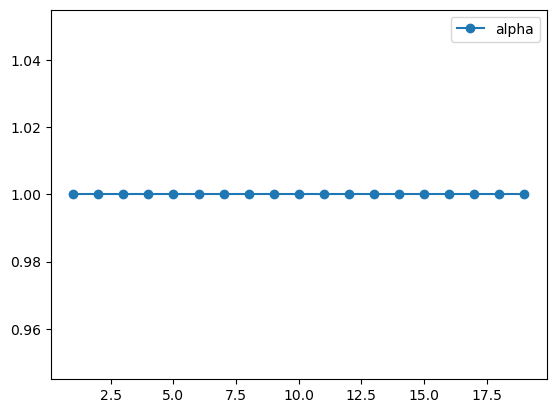

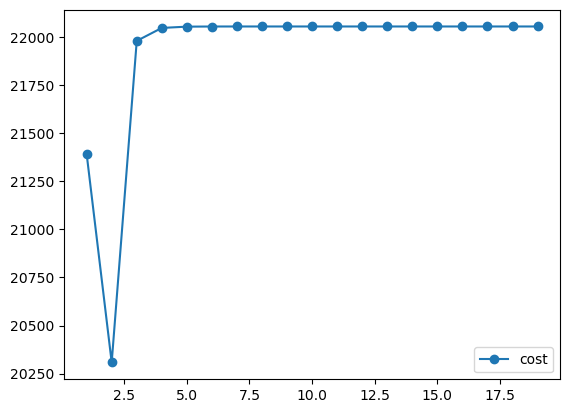

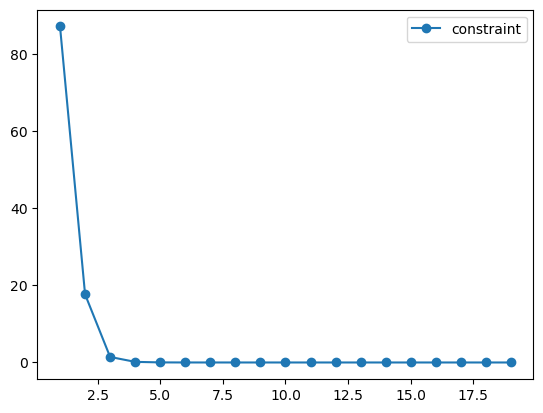

In [19]:
plt.plot(hist["iter"], hist["alpha"], label='alpha', marker='o')
plt.legend()
plt.show()
plt.plot(hist["iter"], hist["J"],  label='cost', marker='o')
plt.legend()
plt.show()
plt.plot(hist["iter"], hist["constraint"], label='constraint',marker='o')
plt.legend()
plt.show()

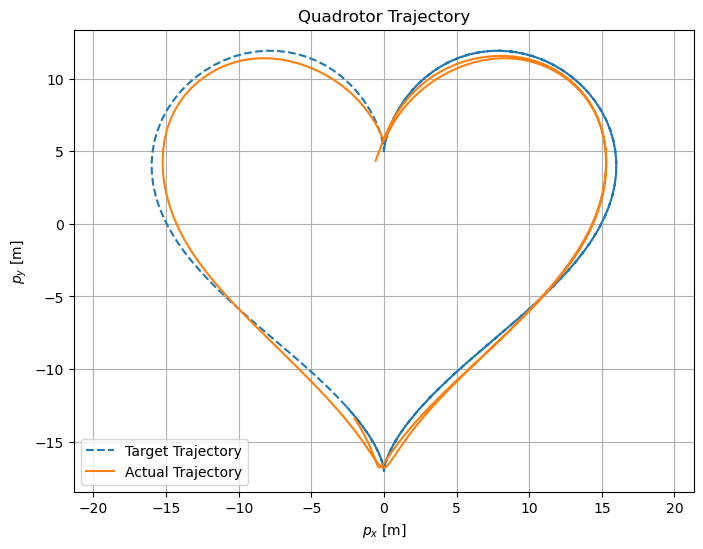

In [20]:
### Plot Results ###
# Trajectory plot
plt.figure(figsize=(8, 6))
plt.plot(px_target, py_target, label='Target Trajectory', linestyle='--')
plt.plot(x[:, 0], x[:, 2], label='Actual Trajectory')
plt.xlabel('$p_x$ [m]')
plt.ylabel('$p_y$ [m]')
plt.title('Quadrotor Trajectory')
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

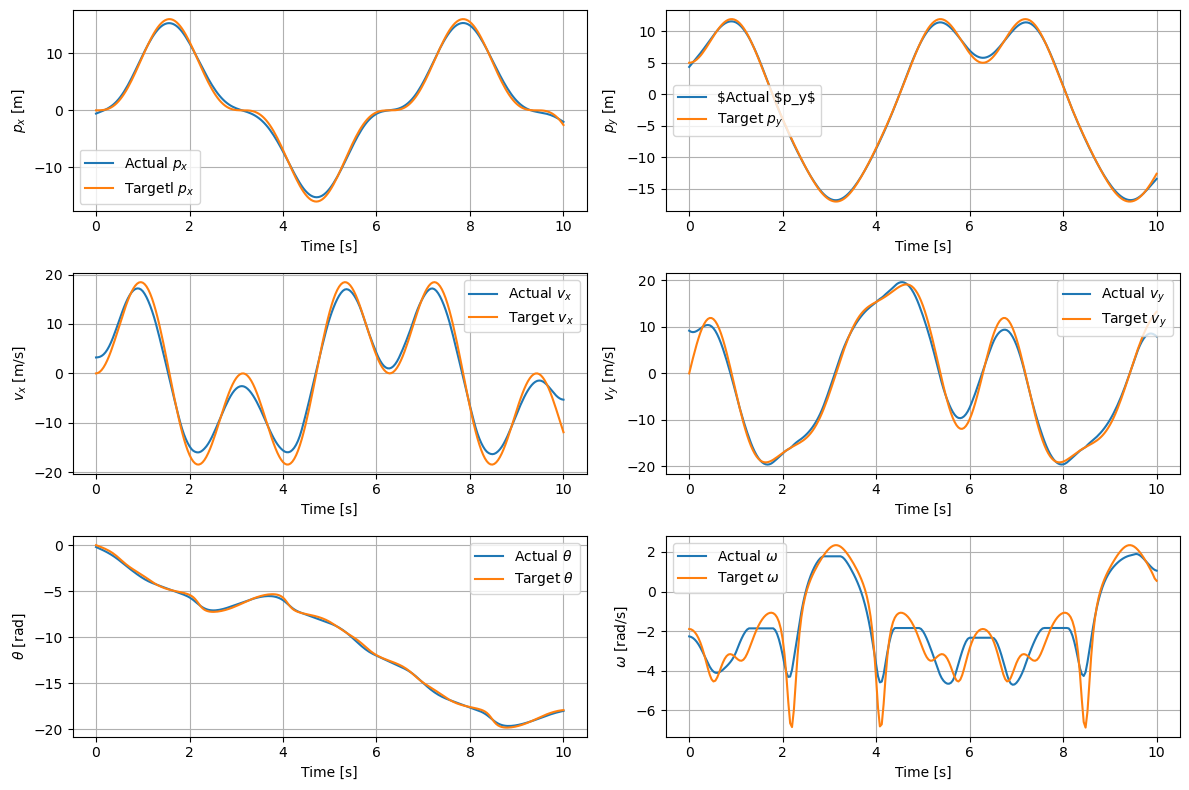

In [21]:
# Time vector
time = np.arange(N + 1) * DT

plt.figure(figsize=(12, 8))

# Position x
plt.subplot(3, 2, 1)
plt.plot(time, x[:, 0], label='Actual $p_x$')
plt.plot(time, px_target,label = 'Targetl $p_x$')
plt.xlabel('Time [s]')
plt.ylabel('$p_x$ [m]')
plt.legend()
plt.grid()

# Position y
plt.subplot(3, 2, 2)
plt.plot(time, x[:, 2], label='$Actual $p_y$')
plt.plot(time, py_target,label = 'Target $p_y$')
plt.xlabel('Time [s]')
plt.ylabel('$p_y$ [m]')
plt.legend()
plt.grid()

# Velocity x
plt.subplot(3, 2, 3)
plt.plot(time, x[:, 1], label='Actual $v_x$')
plt.plot(time, vx_target,label = 'Target $v_x$')
plt.xlabel('Time [s]')
plt.ylabel('$v_x$ [m/s]')
plt.legend()
plt.grid()

# Velocity y
plt.subplot(3, 2, 4)
plt.plot(time, x[:, 3], label='Actual $v_y$')
plt.plot(time, vy_target,label = 'Target $v_y$')
plt.xlabel('Time [s]')
plt.ylabel('$v_y$ [m/s]')
plt.legend()
plt.grid()

# Theta (orientation)
plt.subplot(3, 2, 5)
plt.plot(time, x[:, 4], label='Actual $\\theta$')
plt.plot(time, theta_target,label = 'Target $\\theta$')
plt.xlabel('Time [s]')
plt.ylabel('$\\theta$ [rad]')
plt.legend()
plt.grid()

# Omega (angular velocity)
plt.subplot(3, 2, 6)
plt.plot(time, x[:, 5], label='Actual $\\omega$')
plt.plot(time, omega_target,label = 'Target $\\omega$')
plt.xlabel('Time [s]')
plt.ylabel('$\\omega$ [rad/s]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [22]:
quadrotor1.animate_robot(x.T, u.T)

Your browser does not support the video tag.

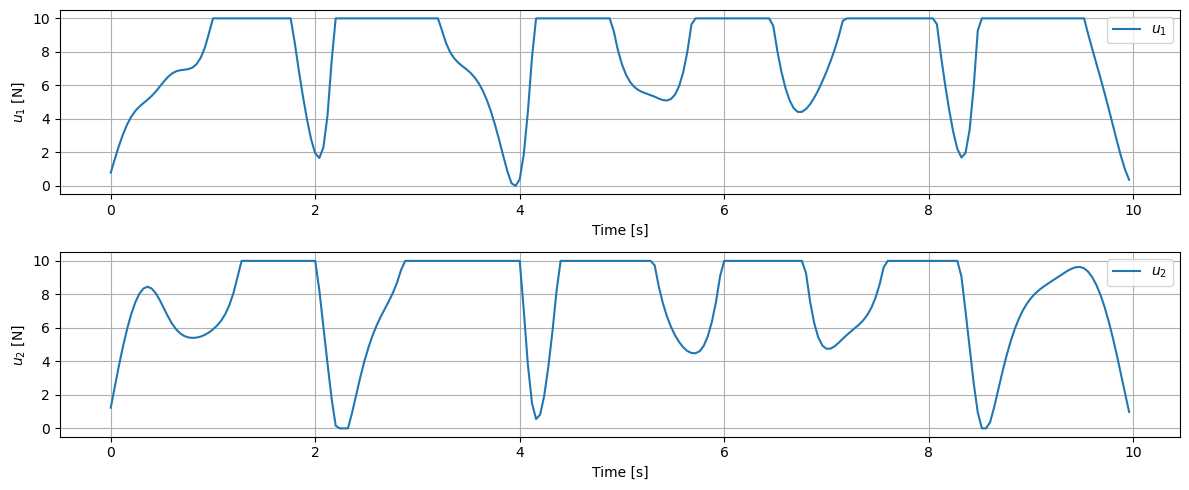

In [23]:
# Control inputs over time
time_controls = np.arange(N) * DT

plt.figure(figsize=(12, 5))

# Rotor thrust u1
plt.subplot(2, 1, 1)
plt.plot(time_controls, u[:, 0], label='$u_1$')
plt.xlabel('Time [s]')
plt.ylabel('$u_1$ [N]')
plt.legend()
plt.grid()

# Rotor thrust u2
plt.subplot(2, 1, 2)
plt.plot(time_controls, u[:, 1], label='$u_2$')
plt.xlabel('Time [s]')
plt.ylabel('$u_2$ [N]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Part 2

In [24]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.animation as animation
import IPython
import quadrotor1
import cvxopt
from cvxopt import matrix, solvers
from scipy.sparse import lil_matrix

# Quadrotor parameters
MASS = quadrotor1.MASS          # 0.5 kg
LENGTH = quadrotor1.LENGTH      # 0.15 m
INERTIA = quadrotor1.INERTIA    # 0.1 kg m^2
DT = quadrotor1.DT              # 0.04 s
G = 9.81                       # Gravity constant
NX = quadrotor1.DIM_STATE       # Number of states
NU = quadrotor1.DIM_CONTROL     # Number of control inputs

In [25]:
# Trajectory parameters
#DURATION = 2
DURATION = 10
N = int(DURATION / DT)
t = np.linspace(0, DURATION, N + 1)

# Cost weights
q_px = 300      # Position weight in x-direction
q_py =300    # Position weight in y-direction
q_v = 1.0       # Velocity weight
q_theta = 10.0  # Orientation weight
q_omega = 10.0  # Angular velocity weight
r_u = 1.0       # Control effort weight

# Cost weight matrices
Q = np.diag([q_px, q_v, q_py, q_v, q_theta, q_omega])
R = r_u * np.eye(NU)

# Looping trajectory parameters
#omega_reference=2*np.pi / DURATION
#T=DURATION
#F0=8*MASS*G
#v0y=0.5*G*T
#y0=0.5*G*(0.5*T)**2

#px_target = F0 / (MASS*omega_reference**2)*np.sin(omega_reference*t)
#py_target = -F0 / (MASS*omega_reference**2)*np.cos(omega_reference*t)-0.5*G*t**2+v0y*t+y0
#vx_target = F0 / (MASS*omega_reference) * np.cos(omega_reference*t)
#vy_target = F0 / (MASS*omega_reference)*np.sin(omega_reference*t)-G*t+v0y
#ax_target = -F0 / MASS* np.sin(omega_reference*t)
#ay_target = F0 / MASS*np.cos(omega_reference*t)-G
#theta_target =  -np.arctan2(ax_target,ay_target + G)
#theta_target = np.unwrap(theta_target)
#omega_target = np.gradient(theta_target, DT)

px_target = 16*np.sin(t)**3
py_target = 13*np.cos(t)- 5*np.cos(2*t) - 2*np.cos(3*t) - np.cos(4*t)
vx_target= 48*np.sin(t)**2*np.cos(t)
vy_target = -13*np.sin(t) + 10*np.sin(2*t) + 6*np.sin(3*t) + 4*np.sin(4*t)
ax_target = 48*np.sin(t)*(3*np.cos(t)**2 - 1)
ay_target = -13*np.cos(t) + 20*np.cos(2*t) + 18*np.cos(3*t) + 16*np.cos(4*t)
theta_target = -np.unwrap(np.arctan2(ax_target, ay_target + G))
omega_target = np.gradient(theta_target, DT)
# Suppressing progress output from cvxopt
solvers.options['show_progress'] = False

In [26]:
### MPC Controller Function ###
def mpc_controller(x_current, t_current):
    # If t_current >= N, return hover control
    if t_current >= N:
        hover_thrust = MASS * G / 2
        return np.array([hover_thrust, hover_thrust])

    # Prediction horizon
    N_p = min(50, N - t_current)

    num_vars = N_p * (NX + NU) + NX  # States and controls

    z0 = np.zeros(num_vars)

    # Initializing z0
    for k in range(N_p):
        idx_k = k * (NX + NU)
        # State x_k
        if k == 0:
            z0[idx_k: idx_k + NX] = x_current
        else:
            #z0[idx_k: idx_k + NX] = z0[idx_k - (NX + NU): idx_k - (NX + NU) + NX]
            z0[idx_k] = px_target[t_current + k]  # p_x
            z0[idx_k + 2] = py_target[t_current + k]  # p_y
            z0[idx_k + 4] = theta_target[t_current + k]  # theta
            z0[idx_k + 1] = vx_target[t_current + k]  # v_x
            z0[idx_k + 3] = vy_target[t_current + k]  # v_y
            z0[idx_k + 5] = omega_target[t_current +k]  #omega
        # Control u_k | initial guess: hover thrust
        hover_thrust = MASS * G / 2
        z0[idx_k + NX: idx_k + NX + NU] = np.array([hover_thrust, hover_thrust])

    # Final state x_{N_p}
    idx_k = N_p * (NX + NU)
    if t_current + N_p <= N:
        z0[idx_k: idx_k + NX] = np.array([
            px_target[t_current + N_p],
            vx_target[t_current + N_p],
            py_target[t_current + N_p],
            vy_target[t_current + N_p],
            theta_target[t_current + N_p],
            omega_target[t_current + N_p]
        ])
    else:
        z0[idx_k: idx_k + NX] = z0[idx_k - (NX + NU): idx_k - (NX + NU) + NX]

    # Solving the MPC optimization problem
    z_solution, hist = mpc_sqp_solver(z0, x_current, t_current, N_p)

    # Extracting the first control input
    u0 = z_solution[NX: NX + NU]
    return u0

In [27]:
### MPC SQP Solver Function ###
solvers.options['show_progress'] = False
def mpc_sqp_solver(z0, x0, t_current, N_p):
    z = z0.copy()
    max_iter = 100
    tol = 1e-4
    rho = 0.5
    f_best = np.inf
    c_best = np.inf
    alpha_min=1e-6
    hist = {
        "iter": [],
        "alpha": [],
        "J": [],
        "constraint": []
           }

    
    num_vars = N_p * (NX + NU) + NX  # States and controls

    lambda_guess_new = np.zeros((N_p) * NX)
    mu_guess_new = np.zeros((2*(N_p) * NU))
    Q = np.diag([q_px, q_v, q_py, q_v, q_theta, q_omega])
    for it in range(max_iter):
        # Computing cost, gradient, Hessian
        J = compute_cost_mpc(z, t_current, N_p)
        grad_J = compute_cost_gradient_mpc(z, t_current, N_p)
        H = compute_cost_hessian_mpc(z, N_p)

        # Computing constraints and Jacobians
        c = compute_constraints_mpc(z, x0, N_p)
        G = compute_constraints_jacobian_mpc(z, x0, N_p).toarray()

        # Computing inequality constraints
        h = compute_inequality_constraints_mpc(z, N_p)
        G_ineq = compute_inequality_constraints_jacobian_mpc(z, N_p).toarray()

        # Setting up QP
        P = cvxopt.matrix(H)
        q = cvxopt.matrix(grad_J)
        Aeq = cvxopt.matrix(G)
        beq = cvxopt.matrix(-c)  # Note the sign change for cvxopt
        G_qp = cvxopt.matrix(G_ineq)
        h_qp = cvxopt.matrix(-h)

        # Solving QP
        try:
            sol = solvers.qp(P, q, G_qp, h_qp, Aeq, beq)
            p = np.array(sol['x']).flatten()
            p_lambda = np.array(sol['y']).flatten()
            p_mu = np.array(sol['z']).flatten()
            if p is None:
                print(f"QP solver failed at iteration {it + 1}")
                break
        except Exception as e:
            print(f"QP solver encountered an error at iteration {it + 1}: {e}")
            break

        # simplified Line search
        alpha = 1.0
        while True:
            z_candidate = z + alpha * p
            J_new = compute_cost_mpc(z_candidate, t_current, N_p)
            c_new = compute_constraints_mpc(z_candidate, x0, N_p)
            total_constraint_violation_new = np.sum(np.abs(c_new))

            if J_new < f_best or total_constraint_violation_new < c_best:
                # Accept the step
                z = z_candidate
                lambda_guess_new = p_lambda
                mu_guess_new = p_mu
                f_best=J_new
                c_best=total_constraint_violation_new

                hist["iter"].append(it + 1)
                hist["alpha"].append(alpha)
                hist["J"].append(J_new)
                hist["constraint"].append(total_constraint_violation_new)
                break
            else:
                alpha *= rho
                if alpha < alpha_min:
                    break
        # Computing optimality
        primal_optimality = np.linalg.norm(grad_J +  G.T @ lambda_guess_new + G_ineq.T @ mu_guess_new)
        dual_optimality = np.linalg.norm(c)


        constraint_violation =  total_constraint_violation_new
   
       # Iteration details, printing just at final iteration
        if((it + 1) % max_iter == 0):
            print("Maximum iterations Reached")
            print(f"tcurrent: {t_current},Itr: {it + 1}, Cost: {round(J_new, 2)}, Constraint Vio.: {round(constraint_violation, 2)}, Alpha: {round(alpha, 8)}, Primal Opt.: {round(primal_optimality, 8)}, Dual Opt.: {round(dual_optimality, 8)}")

        # Checking for convergence
        if primal_optimality < tol and dual_optimality < tol:
            print(f"--- CONVERGED IN {it + 1} ITERATION(S)! ---")
            print(f"tcurrent: {t_current}, Itr: {it + 1}, Cost: {round(J_new, 2)}, Constraint Vio.: {round(constraint_violation, 2)}, Alpha: {round(alpha, 8)}, Primal Opt.: {round(primal_optimality, 8)}, Dual Opt.: {round(dual_optimality, 8)}")
            break
    return z, hist

In [28]:
### Compute Cost MPC Function ###
def compute_cost_mpc(z, t_current, N_p):
    J = 0.0

    for k in range(N_p):
        idx_k = k * (NX + NU)
        x_k = z[idx_k: idx_k + NX]
        u_k = z[idx_k + NX: idx_k + NX + NU]
        if t_current + k <= N:
            x_t = np.array([
                px_target[t_current + k],
                vx_target[t_current + k],
                py_target[t_current + k],
                vy_target[t_current + k],
                theta_target[t_current + k],
                omega_target[t_current + k]
            ])
        else:
            x_t = x_t_prev
        x_t_prev = x_t  # Save for future use

        J += 0.5 * (x_k - x_t).T @ Q @ (x_k - x_t) + 0.5 * u_k.T @ R @ u_k

    # Final state cost
    idx_k = N_p * (NX + NU)
    x_k = z[idx_k: idx_k + NX]
    if t_current + N_p <= N:
        x_t = np.array([
            px_target[t_current + N_p],
            vx_target[t_current + N_p],
            py_target[t_current + N_p],
            vy_target[t_current + N_p],
            theta_target[t_current + N_p],
            omega_target[t_current + N_p]
        ])
    else:
        x_t = x_t_prev

    J += 0.5 * (x_k - x_t).T @ Q @ (x_k - x_t)

    return J

In [29]:
### Compute Cost Gradient MPC Function ###
def compute_cost_gradient_mpc(z, t_current, N_p):
    grad = np.zeros_like(z)

    for k in range(N_p):
        idx_k = k * (NX + NU)
        x_k = z[idx_k: idx_k + NX]
        u_k = z[idx_k + NX: idx_k + NX + NU]
        if t_current + k <= N:
            x_t = np.array([
                px_target[t_current + k],
                vx_target[t_current + k],
                py_target[t_current + k],
                vy_target[t_current + k],
                theta_target[t_current + k],
                omega_target[t_current + k]
            ])
        else:
            x_t = x_t_prev
        x_t_prev = x_t

        grad[idx_k: idx_k + NX] = Q @ (x_k - x_t)
        grad[idx_k + NX: idx_k + NX + NU] = R @ u_k

    # Final state gradient
    idx_k = N_p * (NX + NU)
    x_k = z[idx_k: idx_k + NX]
    if t_current + N_p <= N:
        x_t = np.array([
            px_target[t_current + N_p],
            vx_target[t_current + N_p],
            py_target[t_current + N_p],
            vy_target[t_current + N_p],
            theta_target[t_current + N_p],
            omega_target[t_current + N_p]
        ])
    else:
        x_t = x_t_prev

    grad[idx_k: idx_k + NX] = Q @ (x_k - x_t)

    return grad

In [30]:
# Compute Cost Hessian MPC Function ###
def compute_cost_hessian_mpc(z, N_p):
    H = np.zeros((len(z), len(z)))

    for k in range(N_p):
        idx_k = k * (NX + NU)
        # State Hessian
        H[idx_k: idx_k + NX, idx_k: idx_k + NX] = Q
        # Control Hessian
        H[idx_k + NX: idx_k + NX + NU, idx_k + NX: idx_k + NX + NU] = R

    # Final state Hessian
    idx_k = N_p * (NX + NU)
    H[idx_k: idx_k + NX, idx_k: idx_k + NX] = Q

    return H

In [31]:
### Compute Constraints MPC ###
def compute_constraints_mpc(z, x0, N_p):
    c = np.zeros(N_p * NX)

    for k in range(N_p):
        idx_k = k * (NX + NU)
        idx_kp1 = (k + 1) * (NX + NU)
        if k == 0:
            x_k = x0
        else:
            x_k = z[idx_k: idx_k + NX]
        u_k = z[idx_k + NX: idx_k + NX + NU]
        x_kp1 = z[idx_kp1: idx_kp1 + NX]

        # Dynamics
        f_k = np.zeros(NX)
        f_k[0] = x_k[1]
        f_k[1] = -(u_k[0] + u_k[1]) * np.sin(x_k[4]) / MASS
        f_k[2] = x_k[3]
        f_k[3] = (u_k[0] + u_k[1]) * np.cos(x_k[4]) / MASS - G
        f_k[4] = x_k[5]
        f_k[5] = LENGTH * (u_k[0] - u_k[1]) / INERTIA

        c[k * NX: (k + 1) * NX] = x_kp1 - x_k - DT * f_k

    return c

In [32]:
### Compute Constraints Jacobian MPC Function ###
def compute_constraints_jacobian_mpc(z, x0, N_p):
    num_constraints = N_p * NX
    G = lil_matrix((num_constraints, len(z)))

    for k in range(N_p):
        idx_k = k * (NX + NU)
        idx_kp1 = (k + 1) * (NX + NU)

        if k == 0:
            x_k = x0
            compute_wrt_xk = False  # x_k is x0, constant
        else:
            x_k = z[idx_k: idx_k + NX]
            compute_wrt_xk = True

        u_k = z[idx_k + NX: idx_k + NX + NU]
        x_kp1 = z[idx_kp1: idx_kp1 + NX]

        theta_k = x_k[4]
        u1_k = u_k[0]
        u2_k = u_k[1]

        # Compute partial derivatives
        df_dx = np.zeros((NX, NX))
        df_du = np.zeros((NX, NU))

        df_dx[0, 1] = 1.0

        df_dx[1, 4] = - (u1_k + u2_k) * np.cos(theta_k) / MASS
        df_du[1, 0] = - np.sin(theta_k) / MASS
        df_du[1, 1] = - np.sin(theta_k) / MASS

        df_dx[2, 3] = 1.0

        df_dx[3, 4] = - (u1_k + u2_k) * np.sin(theta_k) / MASS
        df_du[3, 0] = np.cos(theta_k) / MASS
        df_du[3, 1] = np.cos(theta_k) / MASS

        df_dx[4, 5] = 1.0

        df_du[5, 0] = LENGTH / INERTIA
        df_du[5, 1] = - LENGTH / INERTIA

        # Build Jacobian
        # Partial derivatives of c_k w.r.t x_kp1
        G[k * NX: (k + 1) * NX, idx_kp1: idx_kp1 + NX] = np.eye(NX)

        if compute_wrt_xk:
            # Partial derivatives of c_k w.r.t x_k
            G[k * NX: (k + 1) * NX, idx_k: idx_k + NX] = -np.eye(NX) - DT * df_dx

        # Partial derivatives of c_k w.r.t u_k
        G[k * NX: (k + 1) * NX, idx_k + NX: idx_k + NX + NU] = -DT * df_du

    return G.tocsc()

In [33]:
### Compute Inequality Constraints MPC Function ###
def compute_inequality_constraints_mpc(z, N_p):
    h = np.zeros(4 * N_p)
    for k in range(N_p):
        idx_k = k * (NX + NU)
        u_k = z[idx_k + NX: idx_k + NX + NU]
        h[4 * k] = u_k[0] - 10.0        # u1_k <= 10
        h[4 * k + 1] = -u_k[0]          # u1_k >= 0
        h[4 * k + 2] = u_k[1] - 10.0    # u2_k <= 10
        h[4 * k + 3] = -u_k[1]          # u2_k >= 0
    return h

### Compute Inequality Constraints Jacobian MPC Function ###
def compute_inequality_constraints_jacobian_mpc(z, N_p):
    G_ineq = lil_matrix((4 * N_p, len(z)))
    for k in range(N_p):
        idx_k = k * (NX + NU)
        # u1_k constraints
        G_ineq[4 * k, idx_k + NX] = 1.0          # u1_k <= 10
        G_ineq[4 * k + 1, idx_k + NX] = -1.0     # u1_k >= 0
        # u2_k constraints
        G_ineq[4 * k + 2, idx_k + NX + 1] = 1.0  # u2_k <= 10
        G_ineq[4 * k + 3, idx_k + NX + 1] = -1.0 # u2_k >= 0
    return G_ineq.tocsc()

In [ ]:
# Initial state
x_init = np.array([px_target[0], vx_target[0], py_target[0], vy_target[0], theta_target[0], omega_target[0]])
horizon_length = N  # Simulate for the entire duration

import time
# Recording how long this is going to take
start_time = time.time()

# Simulate
t_sim, state_sim, u_sim = quadrotor1.simulate(x_init, mpc_controller, horizon_length, disturbance=False)

# Stopping recording
total_time = time.time()
total_time -= start_time

--- CONVERGED IN 86 ITERATION(S)! ---
tcurrent: 0, Itr: 86, Cost: 11729.78, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.651e-05, Dual Opt.: 0.0
--- CONVERGED IN 81 ITERATION(S)! ---
tcurrent: 1, Itr: 81, Cost: 12039.86, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 9.808e-05, Dual Opt.: 0.0
--- CONVERGED IN 82 ITERATION(S)! ---
tcurrent: 2, Itr: 82, Cost: 12290.48, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.483e-05, Dual Opt.: 0.0


In [ ]:
# Extract positions
px_sim = state_sim[0, :]
py_sim = state_sim[2, :]
plt.figure(figsize=(8, 6))
plt.plot(px_target[:horizon_length+1], py_target[:horizon_length+1], label='Target Trajectory', linestyle='--')
plt.plot(px_sim[:horizon_length+1], py_sim[:horizon_length+1], label='Actual Trajectory')
plt.xlabel('$p_x$ [m]')
plt.ylabel('$p_y$ [m]')
plt.title('Quadrotor Trajectory with MPC & no Disturbances')
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

In [16]:
quadrotor1.animate_robot(state_sim[:horizon_length], u_sim[:horizon_length])

Your browser does not support the video tag.

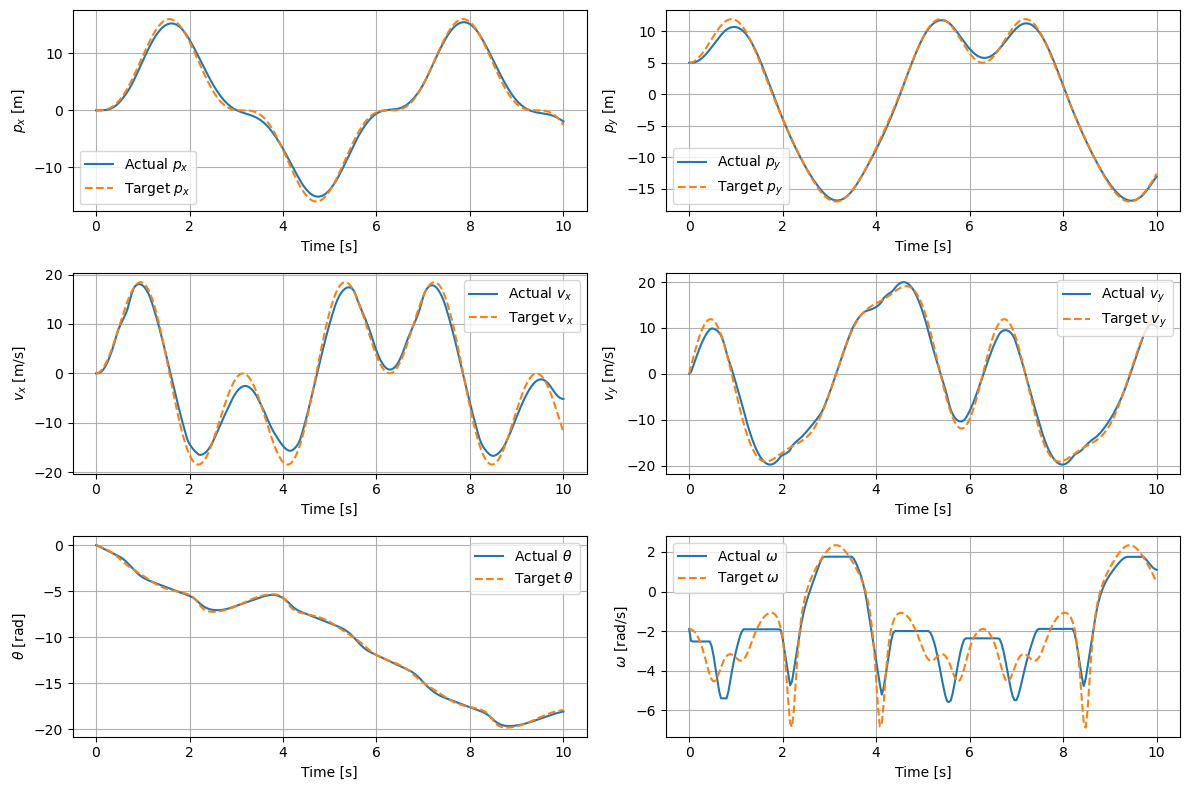

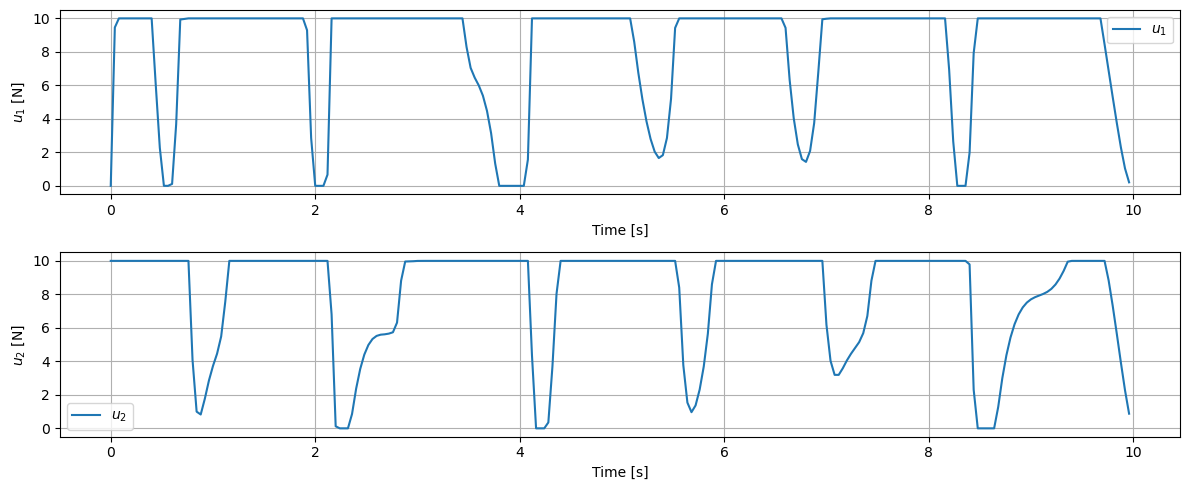

In [19]:
# Time vector
time_sim = t_sim

plt.figure(figsize=(12, 8))

# Position x
plt.subplot(3, 2, 1)
plt.plot(time_sim[:horizon_length+1], state_sim[0, :horizon_length+1], label='Actual $p_x$')
plt.plot(t[:horizon_length+1], px_target[:horizon_length+1], label='Target $p_x$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$p_x$ [m]')
plt.legend()
plt.grid()

# Position y
plt.subplot(3, 2, 2)
plt.plot(time_sim[:horizon_length+1], state_sim[2, :horizon_length+1], label='Actual $p_y$')
plt.plot(t[:horizon_length+1], py_target[:horizon_length+1], label='Target $p_y$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$p_y$ [m]')
plt.legend()
plt.grid()

# Velocity x
plt.subplot(3, 2, 3)
plt.plot(time_sim[:horizon_length+1], state_sim[1, :horizon_length+1], label='Actual $v_x$')
plt.plot(t[:horizon_length+1], vx_target[:horizon_length+1], label='Target $v_x$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$v_x$ [m/s]')
plt.legend()
plt.grid()

# Velocity y
plt.subplot(3, 2, 4)
plt.plot(time_sim[:horizon_length+1], state_sim[3, :horizon_length+1], label='Actual $v_y$')
plt.plot(t[:horizon_length+1], vy_target[:horizon_length+1], label='Target $v_y$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$v_y$ [m/s]')
plt.legend()
plt.grid()

# Theta (orientation)
plt.subplot(3, 2, 5)
plt.plot(time_sim[:horizon_length+1], state_sim[4, :horizon_length+1], label='Actual $\\theta$')
plt.plot(t[:horizon_length+1], theta_target[:horizon_length+1], label='Target $\\theta$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$\\theta$ [rad]')
plt.legend()
plt.grid()

# Omega (angular velocity)
plt.subplot(3, 2, 6)
plt.plot(time_sim[:horizon_length+1], state_sim[5, :horizon_length+1], label='Actual $\\omega$')
plt.plot(t[:horizon_length+1], omega_target[:horizon_length+1], label='Target $\\omega$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$\\omega$ [rad/s]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Control inputs over time
time_controls = time_sim[:-1]

plt.figure(figsize=(12, 5))

# Rotor thrust u1
plt.subplot(2, 1, 1)
plt.plot(time_controls[:horizon_length], u_sim[0, :horizon_length], label='$u_1$')
plt.xlabel('Time [s]')
plt.ylabel('$u_1$ [N]')
plt.legend()
plt.grid()

# Rotor thrust u2
plt.subplot(2, 1, 2)
plt.plot(time_controls[:horizon_length], u_sim[1, :horizon_length], label='$u_2$')
plt.xlabel('Time [s]')
plt.ylabel('$u_2$ [N]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


In [20]:
# Initial state
x_init = np.array([px_target[0], vx_target[0], py_target[0], vy_target[0], theta_target[0], omega_target[0]])
horizon_length = N  # Simulate for the entire duration

import time
# Recording how long this is going to take
start_time = time.time()

# Simulate
t_sim, state_sim, u_sim = quadrotor1.simulate(x_init, mpc_controller, horizon_length, disturbance=True) #with disturbance

# Stopping recording
total_time = time.time()
total_time -= start_time

--- CONVERGED IN 86 ITERATION(S)! ---
tcurrent: 0, Itr: 86, Cost: 11729.78, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.651e-05, Dual Opt.: 0.0
--- CONVERGED IN 69 ITERATION(S)! ---
tcurrent: 1, Itr: 69, Cost: 11689.3, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.072e-05, Dual Opt.: 0.0
--- CONVERGED IN 79 ITERATION(S)! ---
tcurrent: 2, Itr: 79, Cost: 11972.88, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 9.27e-05, Dual Opt.: 0.0
--- CONVERGED IN 69 ITERATION(S)! ---
tcurrent: 3, Itr: 69, Cost: 12191.81, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.204e-05, Dual Opt.: 0.0
--- CONVERGED IN 66 ITERATION(S)! ---
tcurrent: 4, Itr: 66, Cost: 12386.06, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.616e-05, Dual Opt.: 0.0
--- CONVERGED IN 56 ITERATION(S)! ---
tcurrent: 5, Itr: 56, Cost: 12520.54, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 8.726e-05, Dual Opt.: 0.0
--- CONVERGED IN 52 ITERATION(S)! ---
tcurrent: 6, Itr: 52, Cost: 12567.93, Constraint Vio.: 0.0, Alpha: 1.0

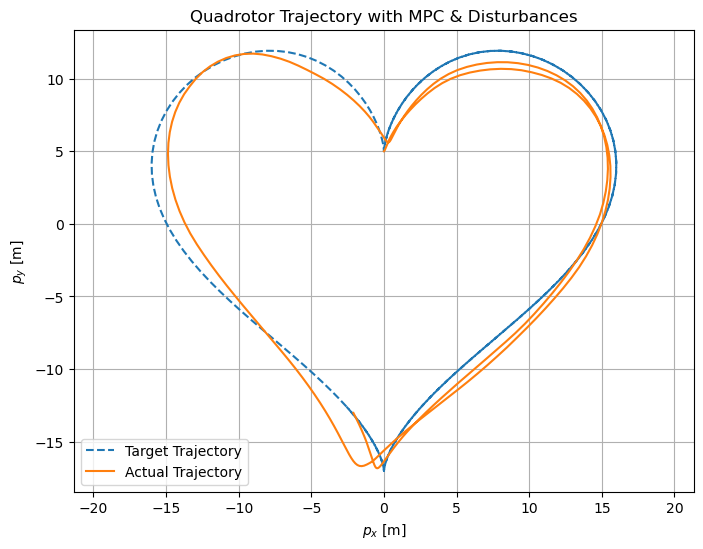

In [21]:
# Extract positions
px_sim = state_sim[0, :]
py_sim = state_sim[2, :]
plt.figure(figsize=(8, 6))
plt.plot(px_target[:horizon_length+1], py_target[:horizon_length+1], label='Target Trajectory', linestyle='--')
plt.plot(px_sim[:horizon_length+1], py_sim[:horizon_length+1], label='Actual Trajectory')
plt.xlabel('$p_x$ [m]')
plt.ylabel('$p_y$ [m]')
plt.title('Quadrotor Trajectory with MPC & Disturbances')
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

In [22]:
quadrotor1.animate_robot(state_sim[:horizon_length], u_sim[:horizon_length])

Your browser does not support the video tag.

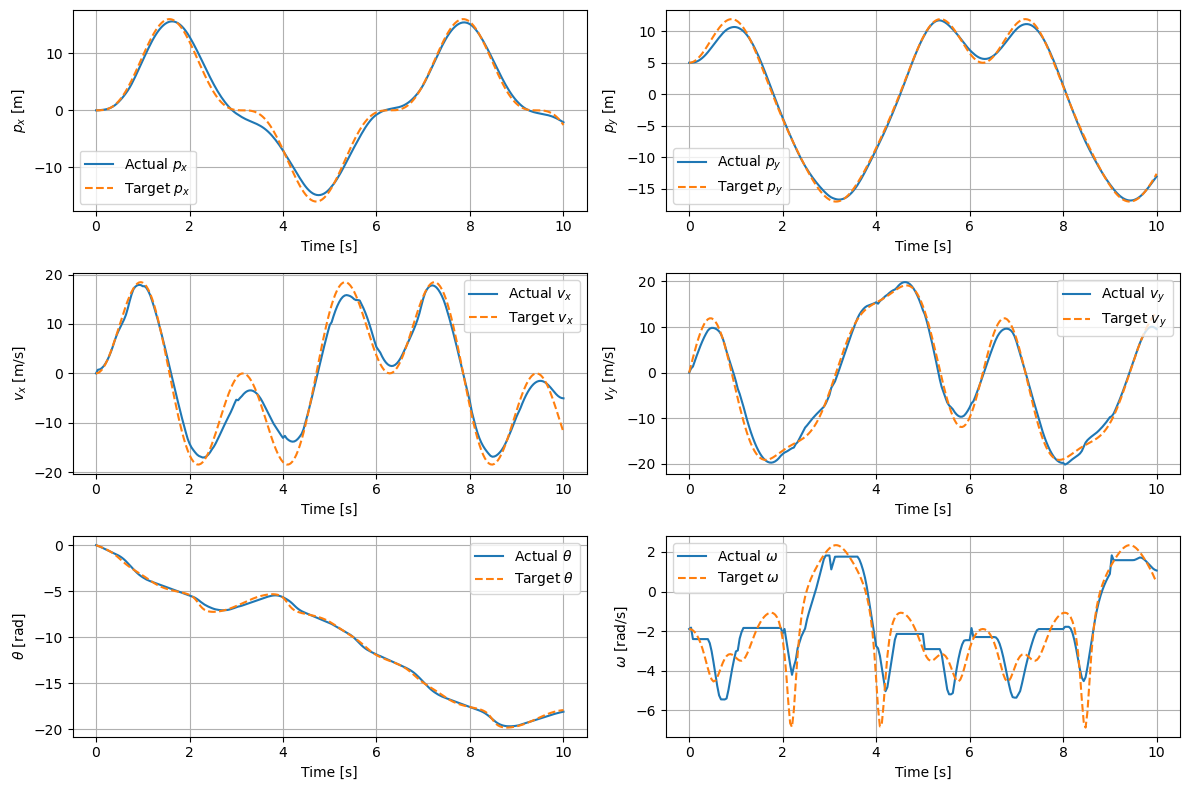

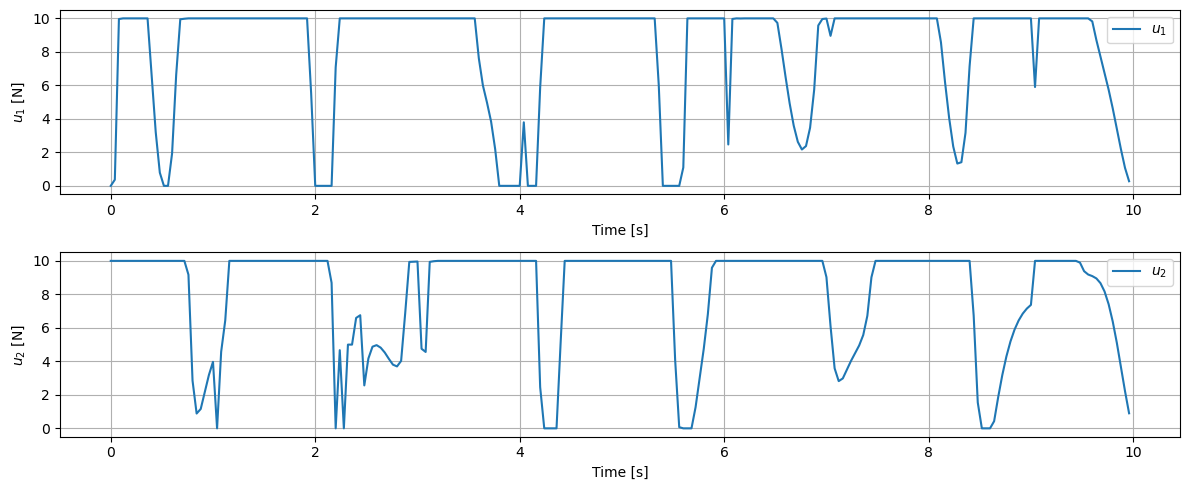

In [23]:
# Time vector
time_sim = t_sim

plt.figure(figsize=(12, 8))

# Position x
plt.subplot(3, 2, 1)
plt.plot(time_sim[:horizon_length+1], state_sim[0, :horizon_length+1], label='Actual $p_x$')
plt.plot(t[:horizon_length+1], px_target[:horizon_length+1], label='Target $p_x$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$p_x$ [m]')
plt.legend()
plt.grid()

# Position y
plt.subplot(3, 2, 2)
plt.plot(time_sim[:horizon_length+1], state_sim[2, :horizon_length+1], label='Actual $p_y$')
plt.plot(t[:horizon_length+1], py_target[:horizon_length+1], label='Target $p_y$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$p_y$ [m]')
plt.legend()
plt.grid()

# Velocity x
plt.subplot(3, 2, 3)
plt.plot(time_sim[:horizon_length+1], state_sim[1, :horizon_length+1], label='Actual $v_x$')
plt.plot(t[:horizon_length+1], vx_target[:horizon_length+1], label='Target $v_x$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$v_x$ [m/s]')
plt.legend()
plt.grid()

# Velocity y
plt.subplot(3, 2, 4)
plt.plot(time_sim[:horizon_length+1], state_sim[3, :horizon_length+1], label='Actual $v_y$')
plt.plot(t[:horizon_length+1], vy_target[:horizon_length+1], label='Target $v_y$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$v_y$ [m/s]')
plt.legend()
plt.grid()

# Theta (orientation)
plt.subplot(3, 2, 5)
plt.plot(time_sim[:horizon_length+1], state_sim[4, :horizon_length+1], label='Actual $\\theta$')
plt.plot(t[:horizon_length+1], theta_target[:horizon_length+1], label='Target $\\theta$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$\\theta$ [rad]')
plt.legend()
plt.grid()

# Omega (angular velocity)
plt.subplot(3, 2, 6)
plt.plot(time_sim[:horizon_length+1], state_sim[5, :horizon_length+1], label='Actual $\\omega$')
plt.plot(t[:horizon_length+1], omega_target[:horizon_length+1], label='Target $\\omega$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$\\omega$ [rad/s]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Control inputs over time
time_controls = time_sim[:-1]

plt.figure(figsize=(12, 5))

# Rotor thrust u1
plt.subplot(2, 1, 1)
plt.plot(time_controls[:horizon_length], u_sim[0, :horizon_length], label='$u_1$')
plt.xlabel('Time [s]')
plt.ylabel('$u_1$ [N]')
plt.legend()
plt.grid()

# Rotor thrust u2
plt.subplot(2, 1, 2)
plt.plot(time_controls[:horizon_length], u_sim[1, :horizon_length], label='$u_2$')
plt.xlabel('Time [s]')
plt.ylabel('$u_2$ [N]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


## Bonus


In [6]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import IPython
import quadrotor1 
import time
import cvxopt
from cvxopt import matrix, solvers
from scipy.sparse import lil_matrix

# Quadrotor parameters
MASS = quadrotor1.MASS          # Mass of the quadrotor (kg)
LENGTH = quadrotor1.LENGTH      # Length of the quadrotor (m)
INERTIA = quadrotor1.INERTIA    # Inertia of the quadrotor (kg·m²)
DT = quadrotor1.DT              # Time step (s)
G = 9.81                       # Gravity constant (m/s²)
NX = quadrotor1.DIM_STATE       # Number of state variables
NU = quadrotor1.DIM_CONTROL     # Number of control inputs

In [7]:
DURATION = 10
N = int(DURATION / DT)
t = np.linspace(0, DURATION, N + 1)

# Cost weights
q_px = 300      # Position weight in x-direction
q_py =300    # Position weight in y-direction
q_v = 1.0       # Velocity weight
q_theta = 10.0  # Orientation weight
q_omega = 10.0  # Angular velocity weight
r_u = 1.0       # Control effort weight

# Cost weight matrices
Q = np.diag([q_px, q_v, q_py, q_v, q_theta, q_omega])
R = r_u * np.eye(NU)

# Looping trajectory parameters
#omega_reference=2*np.pi / DURATION
#T=DURATION
#F0=8*MASS*G
#v0y=0.5*G*T
#y0=0.5*G*(0.5*T)**2

#px_target = F0 / (MASS*omega_reference**2)*np.sin(omega_reference*t)
#py_target = -F0 / (MASS*omega_reference**2)*np.cos(omega_reference*t)-0.5*G*t**2+v0y*t+y0
#vx_target = F0 / (MASS*omega_reference) * np.cos(omega_reference*t)
#vy_target = F0 / (MASS*omega_reference)*np.sin(omega_reference*t)-G*t+v0y
#ax_target = -F0 / MASS* np.sin(omega_reference*t)
#ay_target = F0 / MASS*np.cos(omega_reference*t)-G
#theta_target =  -np.arctan2(ax_target,ay_target + G)
#theta_target = np.unwrap(theta_target)
#omega_target = np.gradient(theta_target, DT)

px_target = 16*np.sin(t)**3
py_target = 13*np.cos(t)- 5*np.cos(2*t) - 2*np.cos(3*t) - np.cos(4*t)
vx_target= 48*np.sin(t)**2*np.cos(t)
vy_target = -13*np.sin(t) + 10*np.sin(2*t) + 6*np.sin(3*t) + 4*np.sin(4*t)
ax_target = 48*np.sin(t)*(3*np.cos(t)**2 - 1)
ay_target = -13*np.cos(t) + 20*np.cos(2*t) + 18*np.cos(3*t) + 16*np.cos(4*t)
theta_target = -np.unwrap(np.arctan2(ax_target, ay_target + G))
omega_target = np.gradient(theta_target, DT)
# Suppressing progress output from cvxopt
solvers.options['show_progress'] = False

In [27]:
### MPC Controller Function ###
def mpc_controller(x_current, t_current):
    # If t_current >= N, return hover control
    if t_current >= N:
        hover_thrust = MASS * G / 2
        return np.array([hover_thrust, hover_thrust])

    # Prediction horizon
    N_p = min(50, N - t_current)

    num_vars = N_p * (NX + NU) + NX  # States and controls

    z0 = np.zeros(num_vars)

    # Initializing z0
    for k in range(N_p):
        idx_k = k * (NX + NU)
        # State x_k
        if k == 0:
            z0[idx_k: idx_k + NX] = x_current
        else:
            z0[idx_k: idx_k + NX] = z0[idx_k - (NX + NU): idx_k - (NX + NU) + NX]
        # Control u_k | initial guess: hover thrust
        hover_thrust = MASS * G / 2
        z0[idx_k + NX: idx_k + NX + NU] = np.array([hover_thrust, hover_thrust])

    # Final state x_{N_p}
    idx_k = N_p * (NX + NU)
    if t_current + N_p <= N:
        z0[idx_k: idx_k + NX] = z0[idx_k - (NX + NU): idx_k - (NX + NU) + NX]

    # Solving the MPC optimization problem
    z_solution, hist = mpc_sqp_solver(z0, x_current, t_current, N_p)

    # Extracting the first control input
    u0 = z_solution[NX: NX + NU]
    return u0

In [28]:
### MPC SQP Solver Function ###
solvers.options['show_progress'] = False
def mpc_sqp_solver(z0, x0, t_current, N_p):
    z = z0.copy()
    max_iter = 200
    tol = 1e-4
    rho = 0.5
    f_best = np.inf
    c_best = np.inf
    alpha_min=1e-6
    hist = {
        "iter": [],
        "alpha": [],
        "J": [],
        "constraint": []
           }

    
    num_vars = N_p * (NX + NU) + NX  # States and controls

    lambda_guess_new = np.zeros((N_p) * NX)
    mu_guess_new = np.zeros(5*(N_p))
    Q = np.diag([q_px, q_v, q_py, q_v, q_theta, q_omega])
    for it in range(max_iter):
        # Computing cost, gradient, Hessian
        J = compute_cost_mpc(z, t_current, N_p)
        grad_J = compute_cost_gradient_mpc(z, t_current, N_p)
        H = compute_cost_hessian_mpc(z, N_p)

        # Computing constraints and Jacobians
        c = compute_constraints_mpc(z, x0, N_p)
        G = compute_constraints_jacobian_mpc(z, x0, N_p).toarray()

        # Computing inequality constraints
        h = compute_inequality_constraints_mpc(z, N_p)
        G_ineq = compute_inequality_constraints_jacobian_mpc(z, N_p).toarray()

        # Setting up QP
        P = cvxopt.matrix(H)
        q = cvxopt.matrix(grad_J)
        Aeq = cvxopt.matrix(G)
        beq = cvxopt.matrix(-c)  # Note the sign change for cvxopt
        G_qp = cvxopt.matrix(G_ineq)
        h_qp = cvxopt.matrix(-h)

        # Solving QP
        try:
            sol = solvers.qp(P, q, G_qp, h_qp, Aeq, beq)
            p = np.array(sol['x']).flatten()
            p_lambda = np.array(sol['y']).flatten()
            p_mu = np.array(sol['z']).flatten()
            if p is None:
                print(f"QP solver failed at iteration {it + 1}")
                break
        except Exception as e:
            print(f"QP solver encountered an error at iteration {it + 1}: {e}")
            break

        # simplified Line search
        alpha = 1.0
        while True:
            z_candidate = z + alpha * p
            J_new = compute_cost_mpc(z_candidate, t_current, N_p)
            c_new = compute_constraints_mpc(z_candidate, x0, N_p)
            total_constraint_violation_new = np.sum(np.abs(c_new))

            if J_new < f_best or total_constraint_violation_new < c_best:
                # Accept the step
                z = z_candidate
                lambda_guess_new = p_lambda
                mu_guess_new = p_mu
                f_best=J_new
                c_best=total_constraint_violation_new

                hist["iter"].append(it + 1)
                hist["alpha"].append(alpha)
                hist["J"].append(J_new)
                hist["constraint"].append(total_constraint_violation_new)
                break
            else:
                alpha *= rho
                if alpha < alpha_min:
                    break
        # Computing optimality
        primal_optimality = np.linalg.norm(grad_J +  G.T @ lambda_guess_new + G_ineq.T @ mu_guess_new)
        dual_optimality = np.linalg.norm(c)


        constraint_violation =  total_constraint_violation_new
   
       # Iteration details, printing just at final iteration
        if((it + 1) % max_iter == 0):
            print("Maximum iterations Reached")
            print(f"tcurrent: {t_current},Itr: {it + 1}, Cost: {round(J_new, 2)}, Constraint Vio.: {round(constraint_violation, 2)}, Alpha: {round(alpha, 8)}, Primal Opt.: {round(primal_optimality, 8)}, Dual Opt.: {round(dual_optimality, 8)}")

        # Checking for convergence
        if primal_optimality < tol and dual_optimality < tol:
            print(f"--- CONVERGED IN {it + 1} ITERATION(S)! ---")
            print(f"tcurrent: {t_current}, Itr: {it + 1}, Cost: {round(J_new, 2)}, Constraint Vio.: {round(constraint_violation, 2)}, Alpha: {round(alpha, 8)}, Primal Opt.: {round(primal_optimality, 8)}, Dual Opt.: {round(dual_optimality, 8)}")
            break
    return z, hist

In [29]:
### Compute Cost MPC Function ###
def compute_cost_mpc(z, t_current, N_p):
    J = 0.0

    for k in range(N_p):
        idx_k = k * (NX + NU)
        x_k = z[idx_k: idx_k + NX]
        u_k = z[idx_k + NX: idx_k + NX + NU]
        if t_current + k <= N:
            x_t = np.array([
                px_target[t_current + k],
                vx_target[t_current + k],
                py_target[t_current + k],
                vy_target[t_current + k],
                theta_target[t_current + k],
                omega_target[t_current + k]
            ])
        else:
            x_t = x_t_prev
        x_t_prev = x_t  # Save for future use

        J += 0.5 * (x_k - x_t).T @ Q @ (x_k - x_t) + 0.5 * u_k.T @ R @ u_k

    # Final state cost
    idx_k = N_p * (NX + NU)
    x_k = z[idx_k: idx_k + NX]
    if t_current + N_p <= N:
        x_t = np.array([
            px_target[t_current + N_p],
            vx_target[t_current + N_p],
            py_target[t_current + N_p],
            vy_target[t_current + N_p],
            theta_target[t_current + N_p],
            omega_target[t_current + N_p]
        ])
    else:
        x_t = x_t_prev

    J += 0.5 * (x_k - x_t).T @ Q @ (x_k - x_t)

    return J

In [30]:
### Compute Cost Gradient MPC Function ###
def compute_cost_gradient_mpc(z, t_current, N_p):
    grad = np.zeros_like(z)

    for k in range(N_p):
        idx_k = k * (NX + NU)
        x_k = z[idx_k: idx_k + NX]
        u_k = z[idx_k + NX: idx_k + NX + NU]
        if t_current + k <= N:
            x_t = np.array([
                px_target[t_current + k],
                vx_target[t_current + k],
                py_target[t_current + k],
                vy_target[t_current + k],
                theta_target[t_current + k],
                omega_target[t_current + k]
            ])
        else:
            x_t = x_t_prev
        x_t_prev = x_t

        grad[idx_k: idx_k + NX] = Q @ (x_k - x_t)
        grad[idx_k + NX: idx_k + NX + NU] = R @ u_k

    # Final state gradient
    idx_k = N_p * (NX + NU)
    x_k = z[idx_k: idx_k + NX]
    if t_current + N_p <= N:
        x_t = np.array([
            px_target[t_current + N_p],
            vx_target[t_current + N_p],
            py_target[t_current + N_p],
            vy_target[t_current + N_p],
            theta_target[t_current + N_p],
            omega_target[t_current + N_p]
        ])
    else:
        x_t = x_t_prev

    grad[idx_k: idx_k + NX] = Q @ (x_k - x_t)

    return grad

In [31]:
# Compute Cost Hessian MPC Function ###
def compute_cost_hessian_mpc(z, N_p):
    H = np.zeros((len(z), len(z)))

    for k in range(N_p):
        idx_k = k * (NX + NU)
        # State Hessian
        H[idx_k: idx_k + NX, idx_k: idx_k + NX] = Q
        # Control Hessian
        H[idx_k + NX: idx_k + NX + NU, idx_k + NX: idx_k + NX + NU] = R

    # Final state Hessian
    idx_k = N_p * (NX + NU)
    H[idx_k: idx_k + NX, idx_k: idx_k + NX] = Q

    return H

In [32]:
### Compute Constraints MPC ###
def compute_constraints_mpc(z, x0, N_p):
    c = np.zeros(N_p * NX)

    for k in range(N_p):
        idx_k = k * (NX + NU)
        idx_kp1 = (k + 1) * (NX + NU)
        if k == 0:
            x_k = x0
        else:
            x_k = z[idx_k: idx_k + NX]
        u_k = z[idx_k + NX: idx_k + NX + NU]
        x_kp1 = z[idx_kp1: idx_kp1 + NX]

        # Dynamics
        f_k = np.zeros(NX)
        f_k[0] = x_k[1]
        f_k[1] = -(u_k[0] + u_k[1]) * np.sin(x_k[4]) / MASS
        f_k[2] = x_k[3]
        f_k[3] = (u_k[0] + u_k[1]) * np.cos(x_k[4]) / MASS - G
        f_k[4] = x_k[5]
        f_k[5] = LENGTH * (u_k[0] - u_k[1]) / INERTIA

        c[k * NX: (k + 1) * NX] = x_kp1 - x_k - DT * f_k

    return c

In [33]:
### Compute Constraints Jacobian MPC Function ###
def compute_constraints_jacobian_mpc(z, x0, N_p):
    num_constraints = N_p * NX
    G = lil_matrix((num_constraints, len(z)))

    for k in range(N_p):
        idx_k = k * (NX + NU)
        idx_kp1 = (k + 1) * (NX + NU)

        if k == 0:
            x_k = x0
            compute_wrt_xk = False  # x_k is x0, constant
        else:
            x_k = z[idx_k: idx_k + NX]
            compute_wrt_xk = True

        u_k = z[idx_k + NX: idx_k + NX + NU]
        x_kp1 = z[idx_kp1: idx_kp1 + NX]

        theta_k = x_k[4]
        u1_k = u_k[0]
        u2_k = u_k[1]

        # Compute partial derivatives
        df_dx = np.zeros((NX, NX))
        df_du = np.zeros((NX, NU))

        df_dx[0, 1] = 1.0

        df_dx[1, 4] = - (u1_k + u2_k) * np.cos(theta_k) / MASS
        df_du[1, 0] = - np.sin(theta_k) / MASS
        df_du[1, 1] = - np.sin(theta_k) / MASS

        df_dx[2, 3] = 1.0

        df_dx[3, 4] = - (u1_k + u2_k) * np.sin(theta_k) / MASS
        df_du[3, 0] = np.cos(theta_k) / MASS
        df_du[3, 1] = np.cos(theta_k) / MASS

        df_dx[4, 5] = 1.0

        df_du[5, 0] = LENGTH / INERTIA
        df_du[5, 1] = - LENGTH / INERTIA

        # Build Jacobian
        # Partial derivatives of c_k w.r.t x_kp1
        G[k * NX: (k + 1) * NX, idx_kp1: idx_kp1 + NX] = np.eye(NX)

        if compute_wrt_xk:
            # Partial derivatives of c_k w.r.t x_k
            G[k * NX: (k + 1) * NX, idx_k: idx_k + NX] = -np.eye(NX) - DT * df_dx

        # Partial derivatives of c_k w.r.t u_k
        G[k * NX: (k + 1) * NX, idx_k + NX: idx_k + NX + NU] = -DT * df_du

    return G.tocsc()

In [34]:
def compute_inequality_constraints_mpc(z, N_p):
    """
    Compute the inequality constraints for the MPC problem.
    Includes control input limits and altitude constraints.
    """
    # Control input constraints
    h = np.zeros(5 * N_p)
    for k in range(N_p):
        idx_k = k * (NX + NU)
        u_k = z[idx_k + NX: idx_k + NX + NU]
        py_k = z[idx_k + 2]
        h[5 * k] = u_k[0] - 10.0        # u1_k <= 10
        h[5 * k + 1] = -u_k[0]          # u1_k >= 0
        h[5 * k + 2] = u_k[1] - 10.0    # u2_k <= 10
        h[5 * k + 3] = -u_k[1]          # u2_k >= 0
        h[5 * k + 4] = -py_k
    return h

def compute_inequality_constraints_jacobian_mpc(z, N_p):
    """
    Compute the Jacobian matrix of the inequality constraints.
    """
    G_ineq = lil_matrix((5 * N_p, len(z)))
    for k in range(N_p):
        idx_k = k * (NX + NU)
        # u1_k constraints
        G_ineq[5 * k, idx_k + NX] = 1.0          # u1_k <= 10
        G_ineq[5 * k + 1, idx_k + NX] = -1.0     # u1_k >= 0
        # u2_k constraints
        G_ineq[5 * k + 2, idx_k + NX + 1] = 1.0  # u2_k <= 10
        G_ineq[5 * k + 3, idx_k + NX + 1] = -1.0 # u2_k >= 0
        G_ineq[5 * k + 4, idx_k + 2] = -1.0

    return G_ineq.tocsc()

In [35]:
# Initial state
x_init = np.array([px_target[0], vx_target[0], py_target[0], vy_target[0], theta_target[0], omega_target[0]])
horizon_length = N  # Simulate for the entire duration

import time
# Recording how long this is going to take
start_time = time.time()

# Simulate
t_sim, state_sim, u_sim = quadrotor1.simulate(x_init, mpc_controller, horizon_length, disturbance=True) #with disturbance

# Stopping recording
total_time = time.time()
total_time -= start_time

--- CONVERGED IN 120 ITERATION(S)! ---
tcurrent: 0, Itr: 120, Cost: 20216.98, Constraint Vio.: 0.0, Alpha: 1.0, Primal Opt.: 9.273e-05, Dual Opt.: 0.0
Maximum iterations Reached
tcurrent: 1,Itr: 200, Cost: 23885.03, Constraint Vio.: 0.36, Alpha: 1.0, Primal Opt.: 162.8888175, Dual Opt.: 0.08299708
Maximum iterations Reached
tcurrent: 2,Itr: 200, Cost: 29118.75, Constraint Vio.: 2.81, Alpha: 1.0, Primal Opt.: 498.55951327, Dual Opt.: 0.65120726
Maximum iterations Reached
tcurrent: 3,Itr: 200, Cost: 36276.13, Constraint Vio.: 1.02, Alpha: 1.0, Primal Opt.: 321.34577357, Dual Opt.: 0.14354899
Maximum iterations Reached
tcurrent: 4,Itr: 200, Cost: 42483.04, Constraint Vio.: 6.41, Alpha: 1.0, Primal Opt.: 746.39534075, Dual Opt.: 1.48791848
Maximum iterations Reached
tcurrent: 5,Itr: 200, Cost: 51664.02, Constraint Vio.: 5.74, Alpha: 1.0, Primal Opt.: 705.2024224, Dual Opt.: 1.37013747
Maximum iterations Reached
tcurrent: 6,Itr: 200, Cost: 62273.54, Constraint Vio.: 3.6, Alpha: 1.0, Primal 

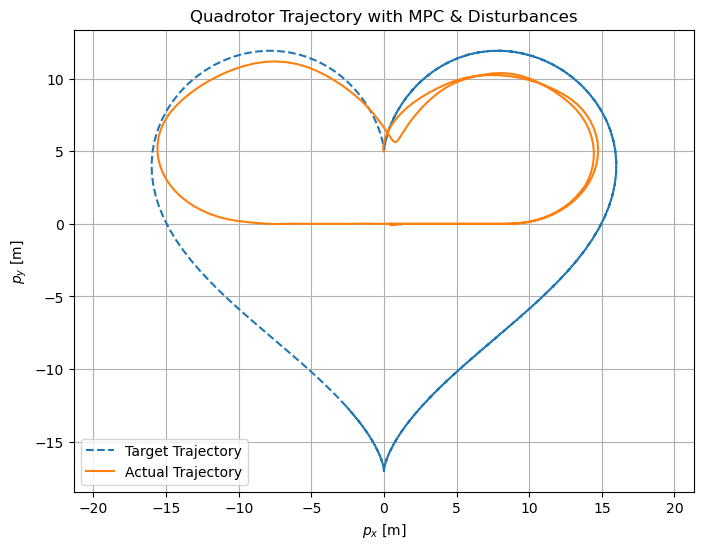

In [36]:
# Extract positions
px_sim = state_sim[0, :]
py_sim = state_sim[2, :]
plt.figure(figsize=(8, 6))
plt.plot(px_target[:horizon_length+1], py_target[:horizon_length+1], label='Target Trajectory', linestyle='--')
plt.plot(px_sim[:horizon_length+1], py_sim[:horizon_length+1], label='Actual Trajectory')
plt.xlabel('$p_x$ [m]')
plt.ylabel('$p_y$ [m]')
plt.title('Quadrotor Trajectory with MPC & Disturbances')
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

In [37]:
quadrotor1.animate_robot(state_sim[:horizon_length], u_sim[:horizon_length])

Your browser does not support the video tag.

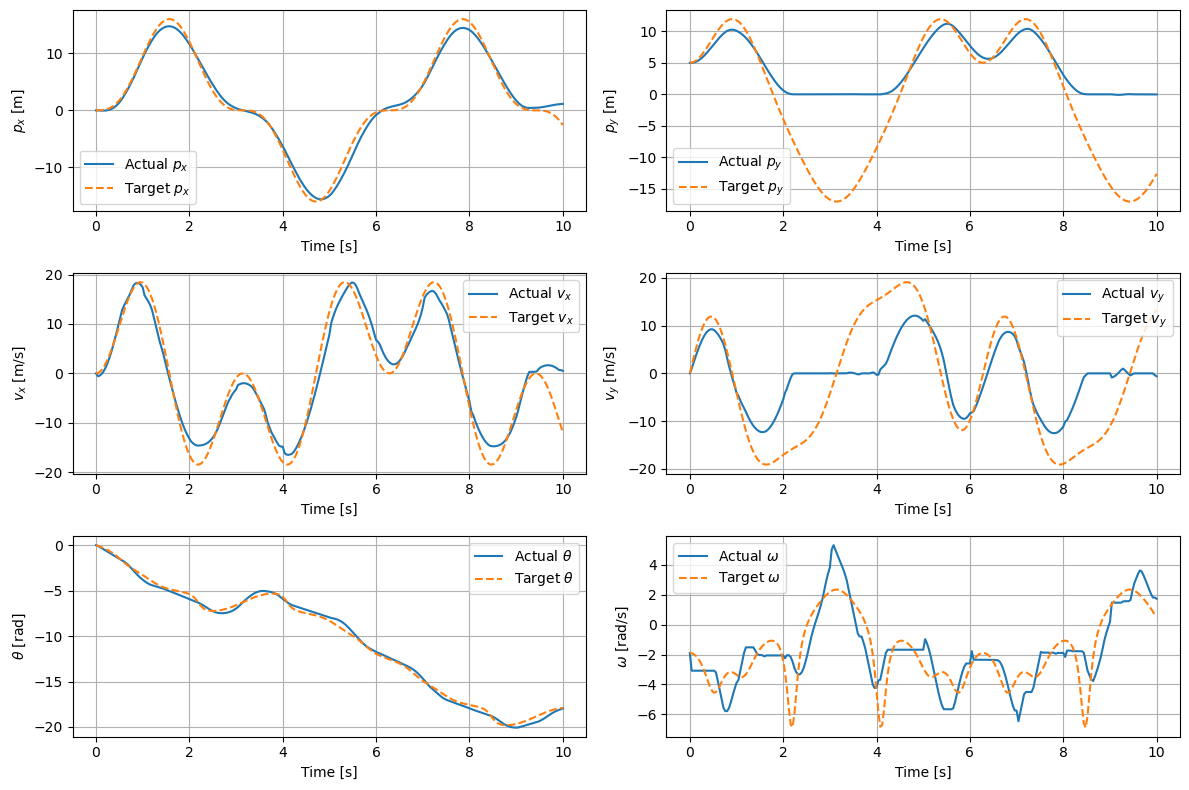

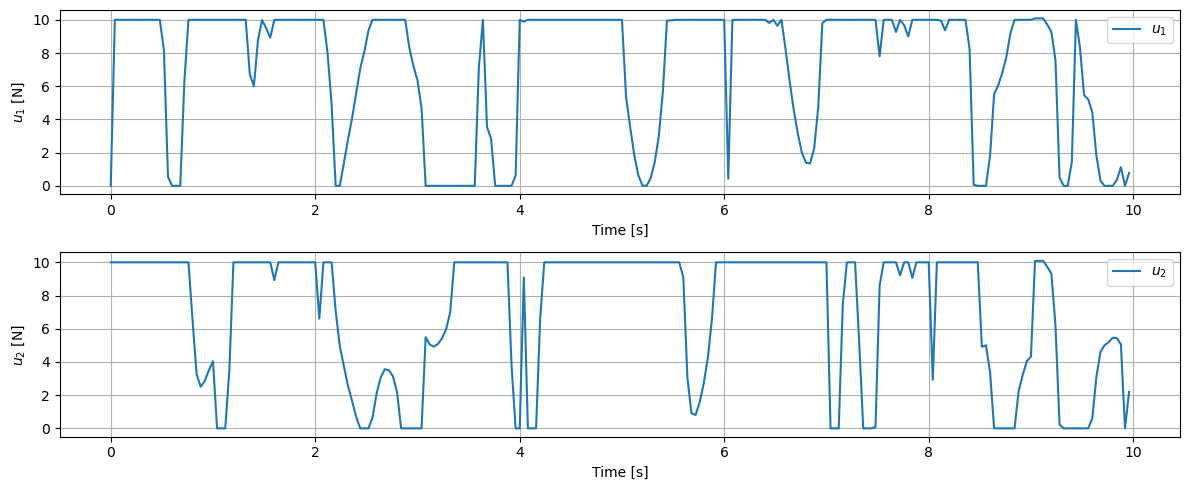

In [38]:
# Time vector
time_sim = t_sim

plt.figure(figsize=(12, 8))

# Position x
plt.subplot(3, 2, 1)
plt.plot(time_sim[:horizon_length+1], state_sim[0, :horizon_length+1], label='Actual $p_x$')
plt.plot(t[:horizon_length+1], px_target[:horizon_length+1], label='Target $p_x$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$p_x$ [m]')
plt.legend()
plt.grid()

# Position y
plt.subplot(3, 2, 2)
plt.plot(time_sim[:horizon_length+1], state_sim[2, :horizon_length+1], label='Actual $p_y$')
plt.plot(t[:horizon_length+1], py_target[:horizon_length+1], label='Target $p_y$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$p_y$ [m]')
plt.legend()
plt.grid()

# Velocity x
plt.subplot(3, 2, 3)
plt.plot(time_sim[:horizon_length+1], state_sim[1, :horizon_length+1], label='Actual $v_x$')
plt.plot(t[:horizon_length+1], vx_target[:horizon_length+1], label='Target $v_x$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$v_x$ [m/s]')
plt.legend()
plt.grid()

# Velocity y
plt.subplot(3, 2, 4)
plt.plot(time_sim[:horizon_length+1], state_sim[3, :horizon_length+1], label='Actual $v_y$')
plt.plot(t[:horizon_length+1], vy_target[:horizon_length+1], label='Target $v_y$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$v_y$ [m/s]')
plt.legend()
plt.grid()

# Theta (orientation)
plt.subplot(3, 2, 5)
plt.plot(time_sim[:horizon_length+1], state_sim[4, :horizon_length+1], label='Actual $\\theta$')
plt.plot(t[:horizon_length+1], theta_target[:horizon_length+1], label='Target $\\theta$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$\\theta$ [rad]')
plt.legend()
plt.grid()

# Omega (angular velocity)
plt.subplot(3, 2, 6)
plt.plot(time_sim[:horizon_length+1], state_sim[5, :horizon_length+1], label='Actual $\\omega$')
plt.plot(t[:horizon_length+1], omega_target[:horizon_length+1], label='Target $\\omega$', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('$\\omega$ [rad/s]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Control inputs over time
time_controls = time_sim[:-1]

plt.figure(figsize=(12, 5))

# Rotor thrust u1
plt.subplot(2, 1, 1)
plt.plot(time_controls[:horizon_length], u_sim[0, :horizon_length], label='$u_1$')
plt.xlabel('Time [s]')
plt.ylabel('$u_1$ [N]')
plt.legend()
plt.grid()

# Rotor thrust u2
plt.subplot(2, 1, 2)
plt.plot(time_controls[:horizon_length], u_sim[1, :horizon_length], label='$u_2$')
plt.xlabel('Time [s]')
plt.ylabel('$u_2$ [N]')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()